# Grupo D — Exportações marítimas de Itajaí e contêineres cheios

Miguel Pezzini Kuhr e Jordan Lippert.

**Pergunta.** Quanto da oscilação mensal do número de contêineres cheios embarcados no Complexo de Itajaí pode ser antecipada com as exportações marítimas já declaradas em Itajaí?

**Tarefa.** Prever os contêineres cheios de um mês X usando só dados até X−1 (contêineres e peso líquido de X−1). Na M3, compara-se a regra “X repete os contêineres de X−1” com o peso líquido de X−1.

Esta entrega é a análise exploratória (M2.2). Aqui montamos o painel mensal, olhamos a cobertura e a associação entre as fontes e não treinamos modelo. Cada pergunta segue o formato **por que perguntamos → gráfico ou medida → conclusão (com n) → limitação**. Os seis últimos meses em que as duas defasagens existem ficam reservados para a M3: aparecem nos gráficos, mas ficam fora das contas da Pergunta 3 e não foram usados para mudar filtro.

**Como rodar.** Na raiz do repositório:

```
python -m venv .venv
.venv\Scripts\activate          (Linux/Mac: source .venv/bin/activate)
pip install -r requirements.txt
```

Depois abra este notebook com o Python do `.venv` e execute de cima para baixo. A primeira célula de código extrai sozinha os zips de `dados/` quando o `.txt` ou `.csv` correspondente ainda não existe. No Kaggle, o conjunto precisa de `antaq/{ano}/{ano}Atracacao.txt`, `antaq/{ano}/{ano}Carga.txt`, `comex/EXP_{ano}.csv` e `dicionarios/`; a primeira célula aponta para `/kaggle/input` quando essa pasta existe.

## Uso de IA neste trabalho

Usamos IA em partes do trabalho e conferimos o que ela produziu.

- **Cursor:** o Miguel usou para organizar a primeira versão do texto e deste notebook.
- **Claude (Cowork):** ajudou o Jordan a comparar opções de tema, a reescrever a pergunta depois do retorno do professor (que pediu separar o problema do método), a definir os filtros da ANTAQ e a checar a integração: somar `QTCarga` em vez de contar linhas e agregar cada fonte por mês antes de juntar.
- **Claude Code:** conferiu as fontes e os links (o endereço antigo `web3.antaq.gov.br` saiu do ar; a ANTAQ publicou até fev/2026 e o Comex até set/2026), revisou as três perguntas, reescreveu os textos neste formato, criou o ambiente (`requirements.txt`) e a extração automática dos zips e gerou o HTML.

O que foi nosso: a escolha do tema, a pergunta e o recorte, os dados (baixados pelo Jordan em 19/10/2026 do painel Estatístico Aquaviário da ANTAQ e da base bruta do MDIC), o repositório, o DOCX e o dicionário de variáveis (Miguel), os filtros e os meses reservados para a M3. Conferimos os filtros na documentação do Estatístico Aquaviário (2026), nos dicionários `URF` e `VIA` e nas amostras de oito linhas. Os números das conclusões foram copiados da saída das células.

In [1]:
from pathlib import Path
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

def achar_entrada_kaggle():
    raiz = Path("/kaggle/input")
    candidatos = [p for p in raiz.iterdir() if p.is_dir()]
    if not candidatos:
        raise FileNotFoundError("Nenhum conjunto em /kaggle/input")
    return candidatos[0]

def extrair_zips(pasta):
    """Extrai cada zip de `pasta` (e subpastas) quando o arquivo de dentro ainda não existe."""
    extraidos = []
    for caminho_zip in sorted(pasta.glob("**/*.zip")):
        with zipfile.ZipFile(caminho_zip) as zf:
            for nome in zf.namelist():
                if not (caminho_zip.parent / nome).exists():
                    zf.extract(nome, caminho_zip.parent)
                    extraidos.append(nome)
    return extraidos

if Path("/kaggle/input").exists():
    BASE = achar_entrada_kaggle()
    RAIZ = BASE
    ANTAQ_ROOT = BASE / "antaq" if (BASE / "antaq").exists() else BASE
    COMEX_DIR = BASE / "comex" if (BASE / "comex").exists() else BASE
    DICT_DIR = BASE / "dicionarios" if (BASE / "dicionarios").exists() else BASE
    OUT_DIR = Path("/kaggle/working")
    ENTREGA = OUT_DIR
else:
    RAIZ = Path.cwd().resolve()
    ANTAQ_ROOT = RAIZ / "dados" / "antaq"
    COMEX_DIR = RAIZ / "dados"
    DICT_DIR = COMEX_DIR / "dicionarios"
    OUT_DIR = RAIZ / "outputs"
    ENTREGA = RAIZ
    novos = extrair_zips(RAIZ / "dados")
    print("Zips extraídos agora:", ", ".join(novos) if novos else "nenhum (os arquivos já estavam extraídos)")

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "figuras").mkdir(exist_ok=True)

def relativo(p):
    try:
        return p.relative_to(RAIZ).as_posix()
    except ValueError:
        return str(p)

print("ANTAQ:", relativo(ANTAQ_ROOT))
print("Comex:", relativo(COMEX_DIR))
print("saída:", relativo(OUT_DIR))
print("pandas", pd.__version__)

Zips extraídos agora: nenhum (os arquivos já estavam extraídos)
ANTAQ: dados/antaq
Comex: dados
saída: outputs
pandas 3.1.0


## Definições fixadas antes de olhar a associação

O alvo é a soma de `QTCarga` no Complexo Portuário Itajaí, com natureza carga conteinerizada, estado cheio, sentido embarcados, `FlagAutorizacao` = S, `FlagMCOperacaoCarga` = 1 e navegação de longo curso. O mês é o `Ano`/`Mes` da atracação, que na documentação da ANTAQ segue a desatracação. Portonave entra nesse complexo. Itapoá fica de fora.

A outra grandeza é a soma de `KG_LIQUIDO` no Comex Stat, URF `0927800` e via `01` (marítima). `VL_FOB` é somado só para constar no painel. `QT_ESTAT` não é somado, porque a unidade muda com o NCM.

Um mês sem arquivo não vira zero. Zero é um mês coberto em que a soma do recorte é nula. A defasagem olha o mês civil anterior, não a observação anterior da tabela.


## Dicionário de variáveis

A unidade é a da grandeza medida. Código, texto e indicador não têm unidade física. `QT_ESTAT` muda com o NCM e por isso não é somada.

### ANTAQ — atracação

| Variável | Descrição | Unidade |
|---|---|---|
| `IDAtracacao` | Identificador da atracação. Liga cada item de carga ao mês e ao porto. | — |
| `Complexo Portuário` | Complexo em que o navio atracou. O recorte fica em Itajaí. | — |
| `Porto Atracação` | Terminal da atracação. Portonave entra nesse complexo. Itapoá fica de fora. | — |
| `Ano` | Ano da desatracação. | ano |
| `Mes` | Mês da desatracação, abreviado (`jan` a `dez`). | mês |

### ANTAQ — carga

| Variável | Descrição | Unidade |
|---|---|---|
| `IDCarga` | Identificador do item de carga. | — |
| `Natureza da Carga` | Classificação da carga. O alvo usa carga conteinerizada. | — |
| `ConteinerEstado` | Estado do contêiner. O alvo usa cheio. | — |
| `Sentido` | Sentido da movimentação. O alvo usa embarcados. | — |
| `Tipo Navegação` | Tipo de navegação. O alvo usa longo curso. A cabotagem só entra na comparação. | — |
| `FlagAutorizacao` | Carga autorizada. O alvo exige `S`. | — |
| `FlagMCOperacaoCarga` | Houve movimentação de carga. O alvo exige `1`. | — |
| `QTCarga` | Quantidade do item. No recorte conteinerizado, a soma mensal é o número de contêineres. | contêiner |

### Comex Stat — exportação

| Variável | Descrição | Unidade |
|---|---|---|
| `CO_ANO` | Ano da declaração de exportação. | ano |
| `CO_MES` | Mês da declaração (`01` a `12`). | mês |
| `CO_NCM` | Código NCM do produto, com oito dígitos. | — |
| `CO_UNID` | Código da unidade estatística daquele NCM. | — |
| `CO_PAIS` | Código do país de destino. | — |
| `SG_UF_NCM` | Sigla da UF do produtor. | — |
| `CO_VIA` | Via de transporte. O recorte usa `01` (marítima). | — |
| `CO_URF` | Unidade da Receita do despacho. O recorte usa `0927800` (Itajaí). | — |
| `QT_ESTAT` | Quantidade na unidade estatística do NCM. Não é somada. | varia com o NCM (kg, un, m, …) |
| `KG_LIQUIDO` | Peso líquido declarado. É a grandeza somada no recorte. | kg |
| `VL_FOB` | Valor FOB. Vai para o painel e não entra nas perguntas. | US$ |

### Painel mensal

Uma linha é um mês civil. Mês sem arquivo fica ausente, não zero. A defasagem é o mês civil anterior.

| Variável | Descrição | Unidade |
|---|---|---|
| `data` | Primeiro dia do mês. | data |
| `ano` | Ano do mês. | ano |
| `mes` | Número do mês, de 1 a 12. | mês |
| `mes_rotulo` | Rótulo `AAAA-MM`. | — |
| `conteineres` | Soma de `QTCarga` no alvo (longo curso). É o alvo da análise. | contêiner |
| `conteineres_cabotagem` | Mesmo filtro, com navegação de cabotagem. | contêiner |
| `conteineres_lag1` | `conteineres` do mês civil anterior. | contêiner |
| `kg_liquido` | Soma de `KG_LIQUIDO` na URF de Itajaí e via marítima. | kg |
| `kg_lag1` | `kg_liquido` do mês civil anterior. | kg |
| `vl_fob` | Soma de `VL_FOB` no mesmo recorte do Comex. | US$ |


In [2]:
MES_MAP = {
    "jan": 1, "fev": 2, "mar": 3, "abr": 4, "mai": 5, "jun": 6,
    "jul": 7, "ago": 8, "set": 9, "out": 10, "nov": 11, "dez": 12,
}
COLS_ATR = ["IDAtracacao", "Complexo Portuário", "Ano", "Mes", "Porto Atracação"]
COLS_CARGA = [
    "IDCarga", "IDAtracacao", "Natureza da Carga", "ConteinerEstado", "Sentido",
    "Tipo Navegação", "FlagAutorizacao", "FlagMCOperacaoCarga", "QTCarga",
]
COLS_EXP = [
    "CO_ANO", "CO_MES", "CO_NCM", "CO_UNID", "CO_PAIS", "SG_UF_NCM",
    "CO_VIA", "CO_URF", "QT_ESTAT", "KG_LIQUIDO", "VL_FOB",
]

def parse_numero(serie):
    s = serie.fillna("").astype(str).str.strip()
    com_virgula = s.str.contains(",", regex=False)
    convertido = s.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    s = s.where(~com_virgula, convertido)
    s = s.replace({"": "0"})
    return pd.to_numeric(s, errors="coerce").fillna(0.0)

def anos_antaq(raiz):
    achados = []
    for pasta in sorted(p for p in raiz.iterdir() if p.is_dir() and p.name.isdigit()):
        ano = pasta.name
        if (pasta / f"{ano}Atracacao.txt").exists() and (pasta / f"{ano}Carga.txt").exists():
            achados.append(int(ano))
    return achados

def rotulo(data):
    return f"{data.year:04d}-{data.month:02d}"

def pearson(df, a, b):
    sub = df[[a, b]].dropna()
    if len(sub) < 3 or sub[a].nunique() < 2 or sub[b].nunique() < 2:
        return len(sub), None
    return len(sub), float(sub[a].corr(sub[b]))

def fmt_int(n):
    return f"{int(n):,}".replace(",", ".")

def fmt_r(r):
    if r is None:
        return "indefinida"
    return f"{r:.2f}".replace(".", ",")

def fmt_dec(x, casas=1):
    """Número com ponto de milhar e vírgula decimal; sem casas quando é inteiro."""
    if float(x).is_integer():
        return fmt_int(x)
    texto = f"{x:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

In [3]:
anos = anos_antaq(ANTAQ_ROOT)
print("Anos ANTAQ encontrados:", anos)
if not anos:
    raise FileNotFoundError(f"Nenhum par Atracacao/Carga em {ANTAQ_ROOT}")

por_ano = {}
n_atr_itajai = 0
n_atr_id_duplicado = 0
for ano in anos:
    pasta = ANTAQ_ROOT / str(ano)
    atr = pd.read_csv(pasta / f"{ano}Atracacao.txt", sep=";", encoding="utf-8-sig", dtype=str, usecols=COLS_ATR)
    atr["Complexo Portuário"] = atr["Complexo Portuário"].fillna("").str.strip()
    it = atr[atr["Complexo Portuário"] == "Itajaí"].copy()
    it["ano"] = pd.to_numeric(it["Ano"], errors="coerce")
    it["mes"] = it["Mes"].fillna("").str.strip().str.lower().map(MES_MAP)
    ruins = it.loc[it["mes"].isna() | it["ano"].isna(), "Mes"].unique().tolist()
    if ruins:
        raise ValueError(f"Mês não mapeado em {ano}: {ruins[:8]}")
    it["ano"] = it["ano"].astype(int)
    it["mes"] = it["mes"].astype(int)
    n_atr_itajai += len(it)
    n_atr_id_duplicado += int(it["IDAtracacao"].duplicated().sum())
    por_ano[ano] = it[["IDAtracacao", "ano", "mes", "Porto Atracação", "Complexo Portuário"]]
    print(f"  {ano}: {len(it)} atracações no complexo, meses {sorted(int(m) for m in it['mes'].unique())}")

atr_ok = pd.concat(por_ano.values(), ignore_index=True)
atr_ok = atr_ok.drop_duplicates("IDAtracacao")
meta = atr_ok.set_index("IDAtracacao")

n_carga_lidas = 0
n_carga_complexo = 0
n_idcarga_duplicado = 0
n_alvo = 0
n_cabo = 0
n_dup_alvo = 0
vistos = set()
vistos_alvo = set()
soma_longo = {}
soma_cabo = {}
amostras_a = []

for ano in anos:
    pasta = ANTAQ_ROOT / str(ano)
    ids = set(por_ano[ano]["IDAtracacao"])
    leitor = pd.read_csv(
        pasta / f"{ano}Carga.txt",
        sep=";",
        encoding="utf-8-sig",
        dtype=str,
        usecols=COLS_CARGA,
        chunksize=300_000,
    )
    lidas_ano = 0
    complexo_ano = 0
    alvo_ano = 0
    for bloco in leitor:
        n_carga_lidas += len(bloco)
        lidas_ano += len(bloco)
        sub = bloco[bloco["IDAtracacao"].isin(ids)]
        if sub.empty:
            continue
        n_carga_complexo += len(sub)
        complexo_ano += len(sub)
        for ident in sub["IDCarga"]:
            if ident in vistos:
                n_idcarga_duplicado += 1
            else:
                vistos.add(ident)
        nat = sub["Natureza da Carga"].fillna("").str.strip()
        est = sub["ConteinerEstado"].fillna("").str.strip()
        sen = sub["Sentido"].fillna("").str.strip()
        nav = sub["Tipo Navegação"].fillna("").str.strip()
        flag_a = sub["FlagAutorizacao"].fillna("").str.strip()
        flag_m = sub["FlagMCOperacaoCarga"].fillna("").str.strip()
        base = (
            (nat == "Carga Conteinerizada")
            & (est == "Cheio")
            & (sen == "Embarcados")
            & (flag_a == "S")
            & (flag_m == "1")
        )
        longo = sub.loc[base & (nav == "Longo Curso")].copy()
        cabo = sub.loc[base & (nav == "Cabotagem")].copy()
        n_alvo += len(longo)
        n_cabo += len(cabo)
        alvo_ano += len(longo)
        for ident in longo["IDCarga"]:
            if ident in vistos_alvo:
                n_dup_alvo += 1
            else:
                vistos_alvo.add(ident)
        for pedaco, destino in ((longo, soma_longo), (cabo, soma_cabo)):
            if pedaco.empty:
                continue
            pedaco = pedaco.join(meta[["ano", "mes"]], on="IDAtracacao")
            pedaco["qt"] = parse_numero(pedaco["QTCarga"])
            for (a, m), valor in pedaco.groupby(["ano", "mes"])["qt"].sum().items():
                chave = (int(a), int(m))
                destino[chave] = destino.get(chave, 0.0) + float(valor)
        if len(amostras_a) < 8 and not longo.empty:
            pedaco = longo.join(meta[["ano", "mes", "Porto Atracação", "Complexo Portuário"]], on="IDAtracacao")
            for _, linha in pedaco.head(8 - len(amostras_a)).iterrows():
                amostras_a.append({
                    "IDCarga": linha["IDCarga"],
                    "IDAtracacao": linha["IDAtracacao"],
                    "Ano": int(linha["ano"]),
                    "Mes": int(linha["mes"]),
                    "Complexo Portuário": linha["Complexo Portuário"],
                    "Porto Atracação": linha["Porto Atracação"],
                    "Natureza da Carga": linha["Natureza da Carga"],
                    "ConteinerEstado": linha["ConteinerEstado"],
                    "Sentido": linha["Sentido"],
                    "Tipo Navegação": linha["Tipo Navegação"],
                    "FlagAutorizacao": linha["FlagAutorizacao"],
                    "FlagMCOperacaoCarga": linha["FlagMCOperacaoCarga"],
                    "QTCarga": linha["QTCarga"],
                })
    print(f"  carga {ano}: {fmt_int(lidas_ano)} linhas lidas, {fmt_int(complexo_ano)} no complexo, {fmt_int(alvo_ano)} no alvo")
    if complexo_ano > 0 and alvo_ano == 0:
        raise RuntimeError(f"Ano {ano} tem carga no complexo e nenhum contêiner no recorte. Conferir rótulos.")

cobertura_antaq = (
    atr_ok[["ano", "mes"]]
    .drop_duplicates()
    .sort_values(["ano", "mes"])
)
somas_antaq = pd.DataFrame(
    [{"ano": a, "mes": m, "conteineres": soma_longo.get((a, m), 0.0),
      "conteineres_cabotagem": soma_cabo.get((a, m), 0.0)}
     for a, m in cobertura_antaq.itertuples(index=False, name=None)]
)
print("Itens de carga no alvo (longo curso):", fmt_int(n_alvo))
print("Itens de carga na cabotagem, mesmo restante do filtro:", fmt_int(n_cabo))


Anos ANTAQ encontrados: [2023, 2024, 2025, 2026]


  2023: 924 atracações no complexo, meses [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


  2024: 886 atracações no complexo, meses [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


  2025: 1188 atracações no complexo, meses [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
  2026: 217 atracações no complexo, meses [1, 2]


  carga 2023: 2.200.645 linhas lidas, 724.195 no complexo, 212.108 no alvo


  carga 2024: 2.439.642 linhas lidas, 680.141 no complexo, 134.972 no alvo


  carga 2025: 2.467.854 linhas lidas, 607.039 no complexo, 113.495 no alvo


  carga 2026: 389.935 linhas lidas, 110.302 no complexo, 20.111 no alvo
Itens de carga no alvo (longo curso): 480.686
Itens de carga na cabotagem, mesmo restante do filtro: 134.797


In [4]:
arquivos_exp = sorted(COMEX_DIR.glob("EXP_*.csv"))
if not arquivos_exp:
    raise FileNotFoundError(f"Nenhum EXP_*.csv em {COMEX_DIR}")

n_comex_lidas = 0
n_comex_recorte = 0
soma_kg = {}
soma_fob = {}
meses_comex = set()
amostras_b = []

for caminho in arquivos_exp:
    lidas = 0
    recorte = 0
    leitor = pd.read_csv(caminho, sep=";", dtype=str, encoding="latin-1", usecols=COLS_EXP, chunksize=400_000)
    for bloco in leitor:
        n_comex_lidas += len(bloco)
        lidas += len(bloco)
        bloco["CO_ANO"] = bloco["CO_ANO"].str.strip()
        bloco["CO_MES"] = bloco["CO_MES"].str.strip()
        for par in bloco.groupby(["CO_ANO", "CO_MES"]).size().index:
            meses_comex.add((int(par[0]), int(par[1])))
        mask = (bloco["CO_URF"].str.strip() == "0927800") & (bloco["CO_VIA"].str.strip() == "01")
        rec = bloco.loc[mask].copy()
        if rec.empty:
            continue
        n_comex_recorte += len(rec)
        recorte += len(rec)
        rec["ano"] = rec["CO_ANO"].astype(int)
        rec["mes"] = rec["CO_MES"].astype(int)
        rec["kg"] = pd.to_numeric(rec["KG_LIQUIDO"], errors="coerce").fillna(0.0)
        rec["fob"] = pd.to_numeric(rec["VL_FOB"], errors="coerce").fillna(0.0)
        for (a, m), grupo in rec.groupby(["ano", "mes"]):
            chave = (int(a), int(m))
            soma_kg[chave] = soma_kg.get(chave, 0.0) + float(grupo["kg"].sum())
            soma_fob[chave] = soma_fob.get(chave, 0.0) + float(grupo["fob"].sum())
        if len(amostras_b) < 8:
            amostras_b.extend(rec.head(8 - len(amostras_b))[COLS_EXP].to_dict("records"))
    print(f"  {caminho.name}: {fmt_int(lidas)} linhas, {fmt_int(recorte)} no recorte")

urf = pd.read_csv(DICT_DIR / "URF.csv", sep=";", dtype=str, encoding="latin-1")
via = pd.read_csv(DICT_DIR / "VIA.csv", sep=";", dtype=str, encoding="latin-1")
nome_urf = urf.loc[urf["CO_URF"] == "0927800", "NO_URF"]
nome_via = via.loc[via["CO_VIA"] == "01", "NO_VIA"]
print("URF:", nome_urf.iloc[0] if len(nome_urf) else "0927800")
print("Via:", nome_via.iloc[0] if len(nome_via) else "01")
print("Linhas no recorte Comex:", fmt_int(n_comex_recorte))


  EXP_2023.csv: 1.563.659 linhas, 41.903 no recorte


  EXP_2024.csv: 1.603.796 linhas, 28.935 no recorte


  EXP_2025.csv: 1.709.746 linhas, 32.555 no recorte


  EXP_2026.csv: 1.272.295 linhas, 30.448 no recorte
URF: 0927800 - ITAJAI
Via: MARITIMA
Linhas no recorte Comex: 133.841


In [5]:
cobertura_comex = pd.DataFrame(sorted(meses_comex), columns=["ano", "mes"])
chaves_comex = list(zip(cobertura_comex["ano"].astype(int), cobertura_comex["mes"].astype(int)))
somas_comex = cobertura_comex.copy()
somas_comex["kg_liquido"] = [soma_kg.get(chave, 0.0) for chave in chaves_comex]
somas_comex["vl_fob"] = [soma_fob.get(chave, 0.0) for chave in chaves_comex]

antaq_m = somas_antaq.copy()
antaq_m["data"] = pd.to_datetime({"year": antaq_m["ano"], "month": antaq_m["mes"], "day": 1})
comex_m = somas_comex.copy()
comex_m["data"] = pd.to_datetime({"year": comex_m["ano"], "month": comex_m["mes"], "day": 1})

inicio = min(antaq_m["data"].min(), comex_m["data"].min())
fim = max(antaq_m["data"].max(), comex_m["data"].max())
grade = pd.DataFrame({"data": pd.date_range(inicio, fim, freq="MS")})
painel = grade.merge(
    antaq_m[["data", "conteineres", "conteineres_cabotagem"]],
    on="data",
    how="left",
)
painel = painel.merge(comex_m[["data", "kg_liquido", "vl_fob"]], on="data", how="left")
painel["ano"] = painel["data"].dt.year
painel["mes"] = painel["data"].dt.month
painel["conteineres_lag1"] = painel["conteineres"].shift(1)
painel["kg_lag1"] = painel["kg_liquido"].shift(1)
painel["mes_rotulo"] = painel["data"].map(rotulo)

ambos = painel["conteineres"].notna() & painel["kg_liquido"].notna()
so_antaq = painel["conteineres"].notna() & painel["kg_liquido"].isna()
so_comex = painel["kg_liquido"].notna() & painel["conteineres"].isna()
lags = painel["conteineres"].notna() & painel["conteineres_lag1"].notna() & painel["kg_lag1"].notna()

painel.to_csv(OUT_DIR / "painel_mensal.csv", index=False)
print(f"Painel de {rotulo(inicio)} a {rotulo(fim)}: {len(painel)} meses civis")
print("Meses com as duas fontes:", int(ambos.sum()))
print("Só ANTAQ:", painel.loc[so_antaq, "mes_rotulo"].tolist() or "nenhum")
print("Só Comex:", painel.loc[so_comex, "mes_rotulo"].tolist())


Painel de 2023-01 a 2026-09: 45 meses civis
Meses com as duas fontes: 38
Só ANTAQ: nenhum
Só Comex: ['2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


## Pergunta 1 — Em quais meses temos as duas fontes, e por que faltam os outros?

**Por que perguntamos isso:** a análise compara contêineres (ANTAQ) com peso exportado (Comex) mês a mês. Antes de calcular qualquer coisa, precisamos saber em quais meses as duas existem e se os buracos são falta de publicação ou falta de movimento. Isso define o n de todas as contas seguintes.

Um mês conta como coberto quando o arquivo daquele ano traz o mês, mesmo que a soma do recorte seja zero. O denominador é o calendário entre o primeiro e o último mês em que alguma das fontes tem arquivo.

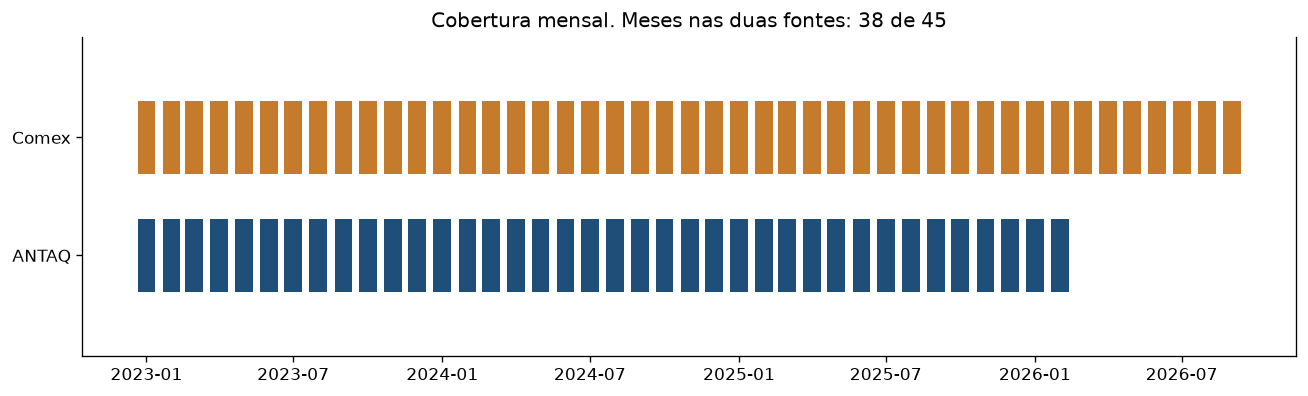

Calendário: 45 meses (2023-01 a 2026-09).
ANTAQ: 38 meses, de 2023-01 a 2026-02. Buracos no meio: nenhum.
Comex: 45 meses, de 2023-01 a 2026-09.
Nas duas fontes: 38 meses. Só no Comex: 7 (2026-03, 2026-04, 2026-05, 2026-06, 2026-07, 2026-08, 2026-09).
Meses só na ANTAQ: nenhum


In [6]:
fig, ax = plt.subplots(figsize=(11, 3.4))
faixas = (
    (0, "ANTAQ", painel["conteineres"].notna(), "#1f4e79"),
    (1, "Comex", painel["kg_liquido"].notna(), "#c47b2b"),
)
for nivel, _nome, serie, cor in faixas:
    ax.bar(
        painel.loc[serie, "data"],
        height=0.62,
        bottom=nivel - 0.31,
        width=22,
        color=cor,
        align="center",
    )
ax.set_yticks([0, 1], ["ANTAQ", "Comex"])
ax.set_ylim(-0.85, 1.85)
ax.set_title(f"Cobertura mensal. Meses nas duas fontes: {int(ambos.sum())} de {len(painel)}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "01_cobertura.png", bbox_inches="tight")
plt.show()

meses_antaq = painel.loc[painel["conteineres"].notna(), "mes_rotulo"]
meses_comex = painel.loc[painel["kg_liquido"].notna(), "mes_rotulo"]
buracos_antaq = painel.loc[
    painel["conteineres"].isna() & (painel["data"] < painel.loc[painel["conteineres"].notna(), "data"].max()),
    "mes_rotulo",
].tolist()
print(f"Calendário: {len(painel)} meses ({rotulo(inicio)} a {rotulo(fim)}).")
print(f"ANTAQ: {len(meses_antaq)} meses, de {meses_antaq.iloc[0]} a {meses_antaq.iloc[-1]}. Buracos no meio: {buracos_antaq or 'nenhum'}.")
print(f"Comex: {len(meses_comex)} meses, de {meses_comex.iloc[0]} a {meses_comex.iloc[-1]}.")
print(f"Nas duas fontes: {int(ambos.sum())} meses. Só no Comex: {int(so_comex.sum())} ({', '.join(painel.loc[so_comex, 'mes_rotulo'])}).")
print("Meses só na ANTAQ:", painel.loc[so_antaq, "mes_rotulo"].tolist() or "nenhum")

**Conclusão (Pergunta 1):** o calendário vai de jan/2023 a set/2026 (45 meses). A ANTAQ cobre **38 meses seguidos**, de jan/2023 a fev/2026, sem buraco no meio; o Comex cobre os 45. As duas fontes se encontram em **38 meses**. Os 7 meses que faltam (mar a set/2026) existem só no Comex. O motivo é de publicação, não de movimento: o painel da ANTAQ mostra “Dados até: fev/2026”, com a última atualização em 01/04/2026 (consulta em 02/11/2026), e em 23/06/2026 a agência avisou que o painel estava indisponível para manutenção. O Comex publicou até set/2026. Esses meses não foram preenchidos com zero.

**Limitação:** a série de contêineres para em fev/2026 e não sabemos quando a ANTAQ volta a publicar. Com 38 meses a série é curta: são 37 pares com o mês anterior, e 6 deles ficam reservados para o teste da M3. Se a ANTAQ atualizar o arquivo de 2026, os números deste notebook mudam.

## Pergunta 2 — O peso declarado no Comex acompanha os contêineres da ANTAQ no mesmo mês?

**Por que perguntamos isso:** as duas fontes medem coisas diferentes. O Comex traz o peso que os exportadores declararam com despacho em Itajaí; a ANTAQ conta os contêineres que de fato saíram nos navios. Se as duas não andarem juntas nem no mesmo mês, juntar as fontes não faz sentido. Também olhamos quantas toneladas declaradas correspondem, em média, a cada contêiner, para ver se essa relação fica estável ao longo do tempo.

A conta usa só os meses em que as duas somas existem. Associação no mesmo mês ainda não é previsão com um mês de antecedência.

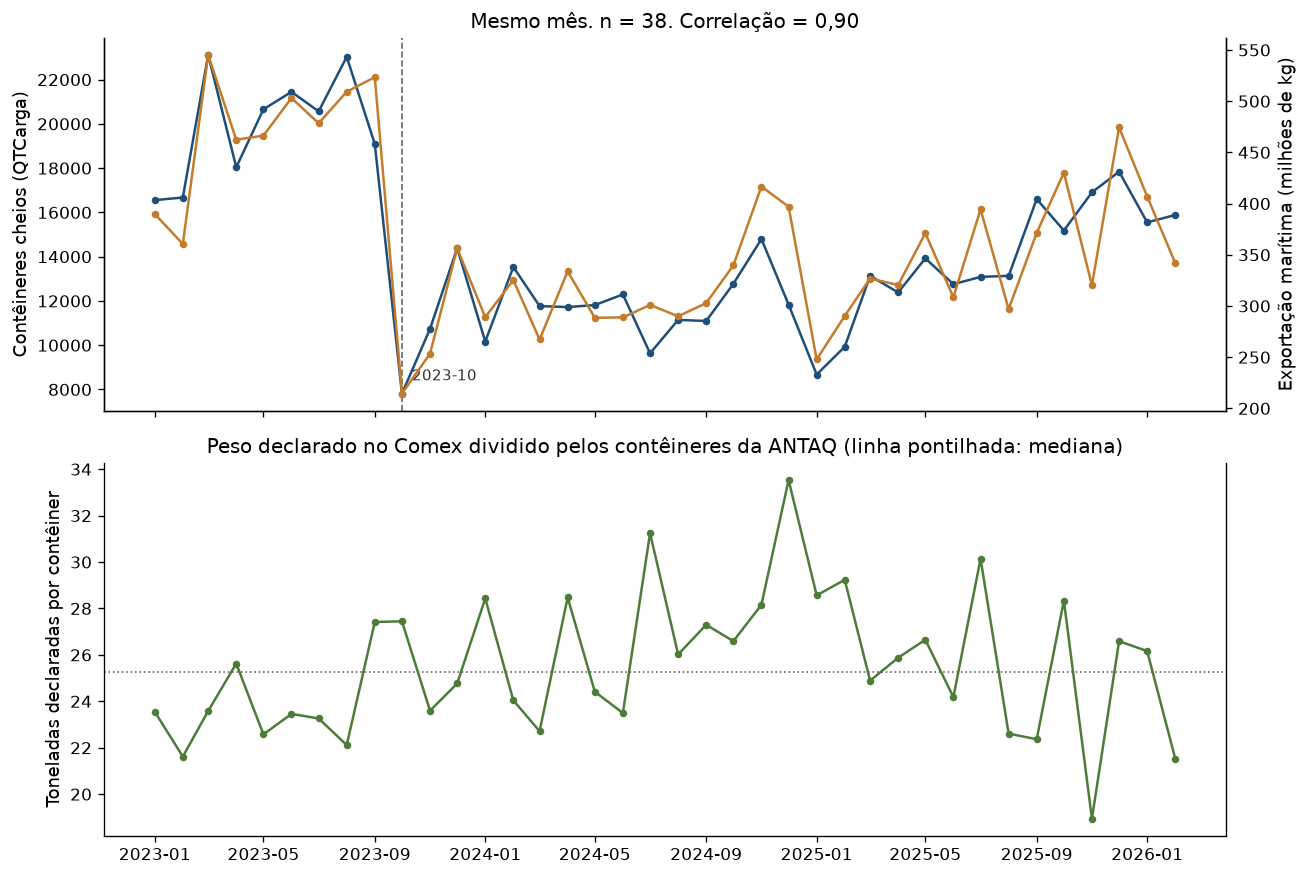

n = 38 meses. Correlação entre contêineres e kg do mesmo mês: 0,90.
Toneladas por contêiner: mínimo 18,9 em 2025-11, mediana 25,3, máximo 33,5 em 2024-12.
Outubro de 2023: 7.811 contêineres e 214 milhões de kg. Mediana dos contêineres nesses meses: 13.333.
Cabotagem (fora do alvo) nos mesmos meses: 160.666 contêineres cheios embarcados.
Ela é 22,6% da soma cabotagem + longo curso.


In [7]:
contemporaneo = painel.loc[ambos].copy()
n_cont, r_cont = pearson(contemporaneo, "conteineres", "kg_liquido")
contemporaneo["t_por_conteiner"] = contemporaneo["kg_liquido"] / 1000 / contemporaneo["conteineres"]

fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(11, 7.4), sharex=True)
ax1.plot(contemporaneo["data"], contemporaneo["conteineres"], color="#1f4e79", marker="o", ms=3.5, label="Contêineres cheios")
ax1.set_ylabel("Contêineres cheios (QTCarga)")
ax2 = ax1.twinx()
ax2.plot(contemporaneo["data"], contemporaneo["kg_liquido"] / 1e6, color="#c47b2b", marker="o", ms=3.5, label="Kg líquido")
ax2.set_ylabel("Exportação marítima (milhões de kg)")
outubro = contemporaneo.loc[contemporaneo["mes_rotulo"] == "2023-10"]
if len(outubro):
    ax1.axvline(outubro["data"].iloc[0], color="#666666", ls="--", lw=1)
    ax1.annotate("2023-10", (outubro["data"].iloc[0], outubro["conteineres"].iloc[0]),
                 textcoords="offset points", xytext=(6, 8), fontsize=9, color="#333333")
ax1.set_title(f"Mesmo mês. n = {n_cont}. Correlação = {fmt_r(r_cont)}")
ax3.plot(contemporaneo["data"], contemporaneo["t_por_conteiner"], color="#4d7c3a", marker="o", ms=3.5)
ax3.axhline(contemporaneo["t_por_conteiner"].median(), color="#666666", ls=":", lw=1)
ax3.set_ylabel("Toneladas declaradas por contêiner")
ax3.set_title("Peso declarado no Comex dividido pelos contêineres da ANTAQ (linha pontilhada: mediana)")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "02_mesmo_mes.png", bbox_inches="tight")
plt.show()

tpc = contemporaneo.set_index("mes_rotulo")["t_por_conteiner"]
med = float(contemporaneo["conteineres"].median())
total_longo = float(contemporaneo["conteineres"].sum())
total_cabo = float(contemporaneo["conteineres_cabotagem"].sum())
parcela_cabo = total_cabo / (total_longo + total_cabo) if (total_longo + total_cabo) else None
print(f"n = {n_cont} meses. Correlação entre contêineres e kg do mesmo mês: {fmt_r(r_cont)}.")
print(f"Toneladas por contêiner: mínimo {fmt_dec(tpc.min())} em {tpc.idxmin()}, mediana {fmt_dec(tpc.median())}, máximo {fmt_dec(tpc.max())} em {tpc.idxmax()}.")
if len(outubro):
    print(
        f"Outubro de 2023: {fmt_int(outubro['conteineres'].iloc[0])} contêineres e "
        f"{outubro['kg_liquido'].iloc[0] / 1e6:.0f} milhões de kg. Mediana dos contêineres nesses meses: {fmt_dec(med)}."
    )
print(f"Cabotagem (fora do alvo) nos mesmos meses: {fmt_int(total_cabo)} contêineres cheios embarcados.")
if parcela_cabo is not None:
    print(f"Ela é {fmt_dec(100 * parcela_cabo)}% da soma cabotagem + longo curso.")

**Conclusão (Pergunta 2):** sim. Nos **38 meses** com as duas fontes, a correlação entre os contêineres cheios de longo curso e o kg exportado no mesmo mês é **0,90**. No gráfico, as duas linhas sobem e descem juntas, inclusive na queda de out/2023 (7.811 contêineres e 214 milhões de kg) e na mudança de patamar depois dela: de jan a set/2023 o alvo ficou entre 16.555 e 23.115 contêineres; de nov/2023 a fev/2026, entre 8.675 (jan/2025) e 17.841 (dez/2025). Isso sustenta juntar as duas fontes pelo mês. A relação entre elas, porém, não é fixa: as toneladas declaradas por contêiner vão de **18,9** (nov/2025) a **33,5** (dez/2024), com mediana de **25,3**, e sobem de 23,6 (mediana de 2023) para 26,9 (2024) e 26,2 (2025). A cabotagem, fora do alvo, soma 160.666 contêineres cheios embarcados nos mesmos meses, 22,6% do total.

**Limitação:** correlação no mesmo mês não é previsão com um mês de antecedência. As toneladas por contêiner misturam duas fontes: o kg do Comex é toda a exportação marítima despachada na URF de Itajaí, não só a que foi em contêiner, e o mês da declaração não é o mês em que o navio saiu. Por isso esse número mostra tendência, não o peso real de um contêiner.

## Pergunta 3 — Os contêineres de um mês acompanham o que aconteceu no mês anterior?

**Por que perguntamos isso:** a pergunta do projeto é sobre antecipar o mês X com o que já se sabe em X−1. Aqui olhamos, sem modelo, se os contêineres de X ficam perto dos contêineres de X−1 e do peso exportado em X−1.

Entram os meses em que existem, ao mesmo tempo, os contêineres de X, os contêineres de X−1 e o kg de X−1. Os seis últimos desses meses ficam reservados para a M3: aparecem no gráfico como círculos vazados, mas ficam fora das correlações, para que o teste da M3 não seja olhado antes. Correlação não é erro de previsão.

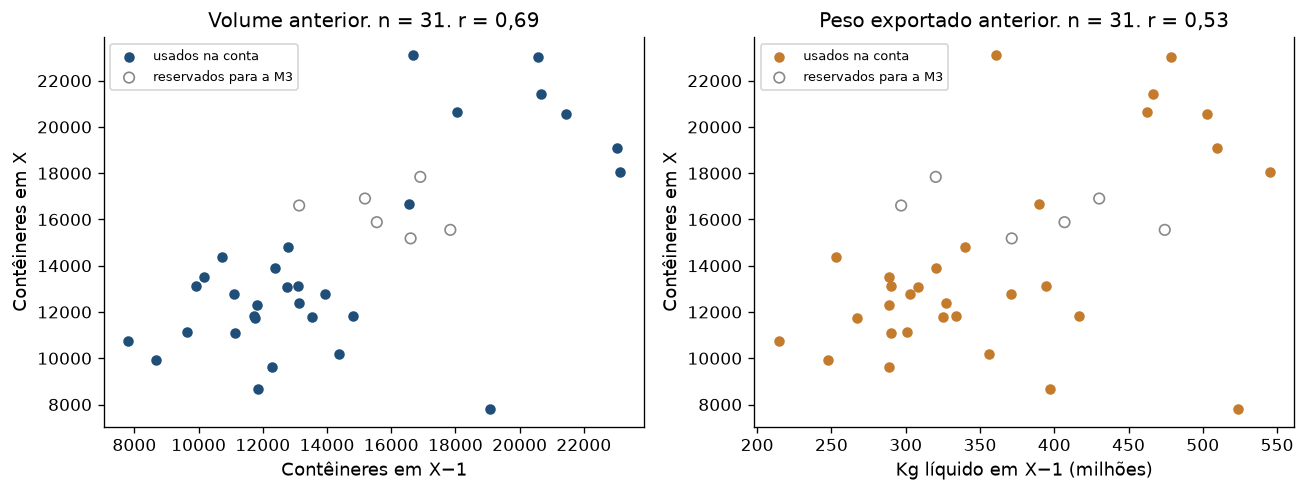

Meses com X, contêineres de X−1 e kg de X−1: 37. Usados nas correlações: 31.
Correlação de X com os contêineres de X−1: 0,69.
Correlação de X com o kg de X−1: 0,53.
Reservados para a M3 (fora das contas): 2025-09, 2025-10, 2025-11, 2025-12, 2026-01, 2026-02


In [8]:
pares = painel.loc[lags].copy()
teste_m3 = pares["mes_rotulo"].tail(6).tolist()
eh_teste = pares["mes_rotulo"].isin(teste_m3)
analise = pares.loc[~eh_teste]
n_pers, r_pers = pearson(analise, "conteineres", "conteineres_lag1")
n_kg, r_kg = pearson(analise, "conteineres", "kg_lag1")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
paineis = (
    (eixos[0], "conteineres_lag1", 1, "#1f4e79", "Contêineres em X−1", f"Volume anterior. n = {n_pers}. r = {fmt_r(r_pers)}"),
    (eixos[1], "kg_lag1", 1e6, "#c47b2b", "Kg líquido em X−1 (milhões)", f"Peso exportado anterior. n = {n_kg}. r = {fmt_r(r_kg)}"),
)
for ax, coluna, escala, cor, rotulo_x, titulo in paineis:
    ax.scatter(analise[coluna] / escala, analise["conteineres"], color=cor, s=28, label="usados na conta")
    ax.scatter(pares.loc[eh_teste, coluna] / escala, pares.loc[eh_teste, "conteineres"],
               facecolors="none", edgecolors="#888888", s=40, label="reservados para a M3")
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel("Contêineres em X")
    ax.set_title(titulo)
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "03_defasagem.png", bbox_inches="tight")
plt.show()

print(f"Meses com X, contêineres de X−1 e kg de X−1: {len(pares)}. Usados nas correlações: {len(analise)}.")
print(f"Correlação de X com os contêineres de X−1: {fmt_r(r_pers)}.")
print(f"Correlação de X com o kg de X−1: {fmt_r(r_kg)}.")
print("Reservados para a M3 (fora das contas):", ", ".join(teste_m3))

**Conclusão (Pergunta 3):** nos **31 meses** usados (37 pares, menos os 6 reservados), a correlação dos contêineres de X com os contêineres de X−1 é **0,69**, e com o kg de X−1 é **0,53**. Ou seja, o volume do mês anterior acompanha o mês seguinte melhor do que o peso exportado no mês anterior. Nos dois gráficos a nuvem tem dois grupos: os meses de 2023 antes de outubro, todos altos, e os demais, mais baixos. Boa parte da correlação vem dessa diferença de patamar. O ponto que mais destoa é out/2023: 7.811 contêineres depois de um setembro alto (19.090 contêineres e 523 milhões de kg).

**Limitação:** correlação na amostra não diz qual regra erra menos ao prever; isso é a M3, nos meses 2025-09 a 2026-02, que ficaram fora destas contas. Com 31 meses e a quebra de 2023, a correlação é sensível a poucos pontos.

## Qualidade da junção e distribuição do alvo

`IDCarga` é a chave do item de carga. `IDAtracacao` se repete porque uma atracação tem vários itens: isso é a cardinalidade esperada, não duplicidade da atracação. No Comex, o mês também se repete, uma vez por NCM. Depois da soma, cada mês aparece uma vez.

O alvo da futura regressão é `conteineres` nos meses cobertos pela ANTAQ. Outubro de 2023 é o menor mês e permanece na série; para entender o valor baixo, contamos as atracações da Portonave, o maior terminal do complexo, em cada mês.

,Etapa,Linhas,Chaves repetidas,Sem correspondência
0,"Fonte A, carga do complexo",2121677,0,não se aplica
1,"Fonte A, recorte do alvo",480686,0,não se aplica
2,"Fonte B, recorte URF e via",133841,133796,não se aplica
3,Mês nas duas fontes,38,0,7


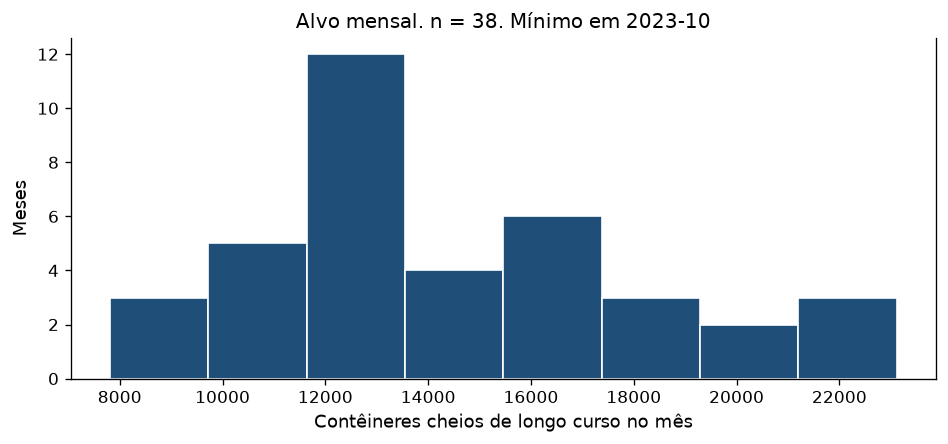

Atracações do complexo: 3.215. IDAtracacao repetido dentro do complexo: 0.
Linhas de carga lidas, todos os portos: 7.498.076.
Linhas de Comex lidas: 6.149.496.
Alvo mensal: n = 38, mínimo = 7.811 em 2023-10, mediana = 13.333, média = 14.465, máximo = 23.115.
Atracações da Portonave em 2023: setembro = 54, outubro = 22, novembro = 34; nos outros meses de 2023, de 51 a 66.
Outubro de 2023 permanece na série; o valor baixo não foi removido.
VL_FOB está no painel e não entra nas três perguntas. QT_ESTAT não foi somado.
Amostras: 8 linhas da ANTAQ e 8 do Comex.
Diagnóstico gravado.


In [9]:
chaves_mes = int(painel["mes_rotulo"].duplicated().sum())
alvo = painel.loc[painel["conteineres"].notna(), "conteineres"]
ordem = painel.loc[painel["conteineres"].notna(), ["mes_rotulo", "conteineres", "kg_liquido"]]
menor = ordem.loc[ordem["conteineres"].idxmin()]
outubro_linha = painel.loc[painel["mes_rotulo"] == "2023-10"]

qualidade = pd.DataFrame([
    {
        "Etapa": "Fonte A, carga do complexo",
        "Linhas": n_carga_complexo,
        "Chaves repetidas": n_idcarga_duplicado,
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Fonte A, recorte do alvo",
        "Linhas": n_alvo,
        "Chaves repetidas": n_dup_alvo,
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Fonte B, recorte URF e via",
        "Linhas": n_comex_recorte,
        "Chaves repetidas": n_comex_recorte - len(soma_kg),
        "Sem correspondência": "não se aplica",
    },
    {
        "Etapa": "Mês nas duas fontes",
        "Linhas": int(ambos.sum()),
        "Chaves repetidas": chaves_mes,
        "Sem correspondência": int(so_antaq.sum() + so_comex.sum()),
    },
])
display(qualidade)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(alvo, bins=8, color="#1f4e79", edgecolor="white")
ax.set_xlabel("Contêineres cheios de longo curso no mês")
ax.set_ylabel("Meses")
ax.set_title(f"Alvo mensal. n = {len(alvo)}. Mínimo em {menor['mes_rotulo']}")
fig.tight_layout()
fig.savefig(OUT_DIR / "figuras" / "04_distribuicao_alvo.png", bbox_inches="tight")
plt.show()

print(f"Atracações do complexo: {fmt_int(n_atr_itajai)}. IDAtracacao repetido dentro do complexo: {n_atr_id_duplicado}.")
print(f"Linhas de carga lidas, todos os portos: {fmt_int(n_carga_lidas)}.")
print(f"Linhas de Comex lidas: {fmt_int(n_comex_lidas)}.")
print(
    f"Alvo mensal: n = {len(alvo)}, mínimo = {fmt_int(menor['conteineres'])} em {menor['mes_rotulo']}, "
    f"mediana = {fmt_dec(alvo.median())}, média = {fmt_dec(alvo.mean(), 0)}, máximo = {fmt_int(alvo.max())}."
)
portonave = "Portonave - Terminais Portuários de Navegantes"
atr_portonave = atr_ok[atr_ok["Porto Atracação"] == portonave].groupby(["ano", "mes"]).size()
atr_2023 = atr_portonave.loc[2023]
print(
    f"Atracações da Portonave em 2023: setembro = {atr_2023.get(9, 0)}, outubro = {atr_2023.get(10, 0)}, "
    f"novembro = {atr_2023.get(11, 0)}; nos outros meses de 2023, de {atr_2023.drop([9, 10, 11]).min()} a {atr_2023.drop([9, 10, 11]).max()}."
)
print("Outubro de 2023 permanece na série; o valor baixo não foi removido.")
print("VL_FOB está no painel e não entra nas três perguntas. QT_ESTAT não foi somado.")

amostra_a = pd.DataFrame(amostras_a)
amostra_b = pd.DataFrame(amostras_b)
for pasta in {OUT_DIR, ENTREGA}:
    amostra_a.to_csv(pasta / "Grupo_D_Fonte_A.csv", sep=";", index=False, encoding="utf-8-sig")
    amostra_b.to_csv(pasta / "Grupo_D_Fonte_B.csv", sep=";", index=False, encoding="utf-8-sig")
print(f"Amostras: {len(amostra_a)} linhas da ANTAQ e {len(amostra_b)} do Comex.")

def num(valor):
    if valor is None or (isinstance(valor, float) and pd.isna(valor)):
        return None
    if hasattr(valor, "item"):
        valor = valor.item()
    return valor

diagnostico = {
    "versoes": {"pandas": pd.__version__},
    "anos_antaq": anos,
    "n_atr_itajai": n_atr_itajai,
    "n_atr_id_duplicado": n_atr_id_duplicado,
    "n_carga_lidas": n_carga_lidas,
    "n_carga_complexo": n_carga_complexo,
    "n_idcarga_duplicado": n_idcarga_duplicado,
    "n_dup_alvo": n_dup_alvo,
    "n_alvo": n_alvo,
    "n_cabo": n_cabo,
    "n_comex_lidas": n_comex_lidas,
    "n_comex_recorte": n_comex_recorte,
    "n_meses_civis": int(len(painel)),
    "n_meses_antaq": int(painel["conteineres"].notna().sum()),
    "n_meses_comex": int(painel["kg_liquido"].notna().sum()),
    "n_meses_ambos": int(ambos.sum()),
    "meses_so_antaq": painel.loc[so_antaq, "mes_rotulo"].tolist(),
    "meses_so_comex": painel.loc[so_comex, "mes_rotulo"].tolist(),
    "meses_ambos": painel.loc[ambos, "mes_rotulo"].tolist(),
    "n_pares_lag": int(len(pares)),
    "r_contemporaneo": num(r_cont),
    "t_por_conteiner_mediana": float(tpc.median()),
    "t_por_conteiner_min": float(tpc.min()),
    "t_por_conteiner_max": float(tpc.max()),
    "n_pares_usados": int(len(analise)),
    "atracacoes_portonave_2023": {int(m): int(v) for m, v in atr_2023.items()},
    "r_persistencia": num(r_pers),
    "r_kg_lag": num(r_kg),
    "parcela_cabotagem": None if parcela_cabo is None else float(parcela_cabo),
    "alvo_n": int(len(alvo)),
    "alvo_min": float(menor["conteineres"]),
    "alvo_min_mes": str(menor["mes_rotulo"]),
    "alvo_mediana": float(alvo.median()),
    "alvo_max": float(alvo.max()),
    "alvo_media": float(alvo.mean()),
    "outubro_2023_conteineres": None if outubro_linha.empty or pd.isna(outubro_linha["conteineres"].iloc[0]) else float(outubro_linha["conteineres"].iloc[0]),
    "outubro_2023_kg": None if outubro_linha.empty or pd.isna(outubro_linha["kg_liquido"].iloc[0]) else float(outubro_linha["kg_liquido"].iloc[0]),
    "teste_m3": teste_m3,
    "chaves_mes_painel": chaves_mes,
    "primeira_data": rotulo(inicio),
    "ultima_data": rotulo(fim),
}
(OUT_DIR / "diagnostico.json").write_text(json.dumps(diagnostico, ensure_ascii=False, indent=2), encoding="utf-8")
print("Diagnóstico gravado.")

**Conclusão (qualidade e alvo):** a junção não duplicou linhas: nenhum `IDCarga` se repete (2.121.677 itens no complexo, 480.686 no alvo), nenhum `IDAtracacao` se repete entre as 3.215 atracações do complexo, e no painel cada mês aparece uma vez (38 meses nas duas fontes, 7 só no Comex). O alvo tem n = 38, mínimo de 7.811 em out/2023, mediana de 13.333, média de 14.465 e máximo de 23.115. Out/2023 não é erro de leitura: as atracações da Portonave caem de 54 em setembro para **22 em outubro** e 34 em novembro, contra 51 a 66 nos outros meses de 2023. O mês fica na série.

**Limitação:** os dados mostram a queda de atracações, mas não dizem a causa. Não houve reamostragem nem corte de cauda; com 38 meses, os meses baixos de 2023 pesam bastante em qualquer média.